# Overall Bias and Noise Comparisons: Full Defaults vs Adjusted Settings

The same one-figure-per-metric summary as `overall_bias_comparisons.ipynb`, except that the
left-hand panel of every heatmap is each package run with its **full defaults**, exactly as it
comes out of the box:

| | Full defaults (left) |
|---|---|
| **PyMC** | `pm.fit` defaults: ADVI, `adagrad_window`, 1 MC sample, 10,000 iterations |
| **NumPyro** | `AutoNormal`, `Trace_ELBO()` (1 MC sample), `Adam(5e-4)`, 30,000 iterations |
| **TFP** | `build_factored_surrogate_posterior` with **no transformation** (a Normal surrogate on the model's own parameters), `tf.optimizers.Adam()`, 1 MC sample, 10,000 iterations |
| **Stan** | every CmdStan ADVI default: `iter=10000`, `tol_rel_obj=0.01`, 1,000 output draws, 1 MC sample |

NumPyro and TFP have no default number of iterations; 30,000 and 10,000 are the numbers we use
as their defaults. On the Multinomial-Dirichlet, PyMC and Stan use their own default simplex
transforms. Each setup is run for 10 seeds (Stan included), keeping the last 500 iterations,
and every fit is timed (wall clock, see *Fit times* below).

The right-hand panel ("Using adjusted settings") changes one setting at a time:

| | Adjusted settings (right) |
|---|---|
| **TFP** | with the transformations (bijectors) added by hand, 1 MC sample, 10,000 iterations |
| **PyMC** | 50,000 iterations with the default optimizer; with Adam; with 100 MC samples |
| **Stan** | 1 MC sample, `tol_rel_obj=1e-6`, 10,000 output draws, 25,000 iterations; the same with 100 MC samples |

The PyMC and Stan runs are the saved runs of `overall_bias_comparisons.ipynb` (`overall_bias_results/`;
the Journé et al. example's PyMC runs are 75,000 iterations; Stan has 5 seeds). TFP is run for this
notebook into `overall_bias_results_1mc/` (`overall_bias_results_1mc/run_right_panel.sh`).

Two consequences of the full defaults to keep in mind when reading the heatmaps:

- **Stan** stops as soon as the relative ELBO change is below `tol_rel_obj=0.01`, which is usually long
  before 10,000 iterations, so the 500 reruns of the window are the same fit and its within-seed
  noise is (numerically) zero.
- **TFP** without a transformation fits a Normal on the constrained parameters themselves (a Beta
  probability, a Gamma rate, a simplex, the radon σ's), so its surrogate can sit partly outside the
  support. In radon, σ_a and σ_y converge to negative values in some seeds; those seeds count as failed
  fits of that σ (see the § footnote), and the positive fits are taken to the log scale for the Radon (log σ) row.

**Metrics.** As in `overall_bias_comparisons.ipynb`: for one seed, $\langle\mu\rangle$ and
$\langle\sigma\rangle$ are the VI posterior mean and SD averaged over the last `WINDOW_ITERS`
iterations and $\mu^*$, $\sigma^*$ the best variational approximation.

| # | Heatmap | Definition |
|---|---|---|
| 1 | Relative bias of the VI posterior mean $\mu$ | mean over seeds of $\lvert \langle\mu\rangle - \mu^* \rvert / \lvert \mu^* \rvert$ |
| 2 | Relative bias of the VI posterior SD $\sigma$ | mean over seeds of $\lvert \langle\sigma\rangle - \sigma^* \rvert / \sigma^*$ |
| 3 | Relative between-seed noise of the VI posterior mean $\mu$ | $\mathrm{SD}_{\text{seeds}}\big(\langle\mu\rangle / \lvert \mu^* \rvert\big)$ |
| 4 | Relative between-seed noise of the VI posterior SD $\sigma$ | $\mathrm{SD}_{\text{seeds}}\big(\langle\sigma\rangle / \sigma^*\big)$ |
| 5 | Relative within-seed noise of the VI posterior mean $\mu$ | $\sqrt{\text{mean over seeds of } \mathrm{Var}_{\text{window}}\big(\mu / \lvert \mu^* \rvert\big)}$ |
| 6 | Relative within-seed noise of the VI posterior SD $\sigma$ | $\sqrt{\text{mean over seeds of } \mathrm{Var}_{\text{window}}\big(\sigma / \sigma^*\big)}$ |
| 7 | Error of the VI posterior mean $\mu$ in units of the best SD $\sigma^*$ | mean over seeds of $\lvert \langle\mu\rangle - \mu^* \rvert / \sigma^*$ |

Multi-dimensional models are combined over their coordinates with the mean (the per-coordinate
heatmaps are in `overall_bias_comparisons.ipynb` only).

**Layout.** Every table and heatmap function lives in `overall_bias_runners/bias_heatmaps.py`, shared
with `overall_bias_comparisons.ipynb`, so both notebooks compute and draw the metrics with the same
code. Part 1 runs the full-default fits (`run_all_runners.sh` with `FULL_DEFAULT=1`, then
`Perennial_reproduction/run_journe_restarts.sh` with `FULL_DEFAULTS=1`) into
`overall_bias_results_full_default/` (the right panel's TFP runs are
`overall_bias_results_1mc/run_right_panel.sh`); Part 2 only reads results. Set `PLOT_ONLY = True` to skip Part 1.

In [1]:
import os
import shlex
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# skip every cell that runs / saves random restarts and only read + plot
PLOT_ONLY = True


def find_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "modulars").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate repo root containing modulars/")


REPO_ROOT = find_repo_root()
PAPER_VIGNETTES = REPO_ROOT / "paper_vignettes"
RUNNERS_DIR = PAPER_VIGNETTES / "overall_bias_runners"
# adjusted settings (right panel), as overall_bias_comparisons.ipynb
RESULTS_DIR = Path(os.environ.get("OVERALL_BIAS_RESULTS_DIR", PAPER_VIGNETTES / "overall_bias_results")).resolve()
# full defaults (left panel)
FULL_DEFAULT_RESULTS_DIR = Path(os.environ.get("OVERALL_BIAS_FULL_DEFAULT_RESULTS_DIR",
                                               PAPER_VIGNETTES / "overall_bias_results_full_default")).resolve()

# right panel's TFP 1 MC runs (10k iterations)
SINGLE_SETUP_RESULTS_DIR = Path(os.environ.get("OVERALL_BIAS_1MC_RESULTS_DIR",
                                               PAPER_VIGNETTES / "overall_bias_results_1mc")).resolve()

if str(RUNNERS_DIR) not in sys.path:
    sys.path.insert(0, str(RUNNERS_DIR))
import bias_io  # numpy / pandas only, shared with the runners
import bias_heatmaps as bh  # the tables and heatmaps, shared with overall_bias_comparisons.ipynb

print(f"repo root:                  {REPO_ROOT}")
print(f"adjusted results dir:       {RESULTS_DIR}")
print(f"full-default results dir:   {FULL_DEFAULT_RESULTS_DIR}")
print(f"1 MC results dir:           {SINGLE_SETUP_RESULTS_DIR}")

repo root:                  /Users/madelynandersen/Documents/VB Bakeoff/simpleVI
adjusted results dir:       /Users/madelynandersen/Documents/VB Bakeoff/simpleVI/paper_vignettes/overall_bias_results
full-default results dir:   /Users/madelynandersen/Documents/VB Bakeoff/simpleVI/paper_vignettes/overall_bias_results_full_default
1 MC results dir:           /Users/madelynandersen/Documents/VB Bakeoff/simpleVI/paper_vignettes/overall_bias_results_1mc


## Part 1: run and save the full-default fits

`run_all_runners.sh` with `FULL_DEFAULT=1` runs every runner with `--full-default 1`: only the
1 MC sample fit, each package's default number of iterations, `RUN_N_SEEDS` seeds for every package
(Stan included), the last `RUN_WINDOW` iterations tracked, saved as setup `full_default` with each
seed's fit time. The packages run one after the other so the fit times aren't slowed by each other.
Then `Perennial_reproduction/run_journe_restarts.sh` with `FULL_DEFAULTS=1` does the same for the
Journé et al. example. The adjusted settings on the right are the runs of `overall_bias_comparisons.ipynb`.

In [2]:
# run settings, passed to the two launchers (each is also overridable there)
RUN_N_SEEDS = 10
RUN_WINDOW = 500                  # tracked final iterations
RUN_OVERWRITE = 0                 # 1 reruns and overwrites saved results
RUN_PACKAGES = ["pymc", "tfp", "numpyro", "stan"]
RUN_MODELS = list(bias_io.MODEL_KEYS)
RUN_JOURNE = True                 # also the Journé et al. example (Perennial_reproduction/run_journe_restarts.sh)

# "print": show the command to paste into a terminal
# "background": launch it detached from this kernel, logging to overall_bias_results_full_default/logs/
# "foreground": run it inside this kernel and wait for it to finish
RUN_MODE = "print"

In [3]:
if PLOT_ONLY:
    print("PLOT_ONLY = True: skipping the full-default runs")
else:
    suite_env = {
        "FULL_DEFAULT": "1",
        "N_SEEDS": str(RUN_N_SEEDS),
        "WINDOW": str(RUN_WINDOW),
        "OVERWRITE": str(RUN_OVERWRITE),
        "PACKAGES": " ".join(RUN_PACKAGES),
        "MODELS": " ".join(RUN_MODELS),
        "RESULTS_DIR": str(FULL_DEFAULT_RESULTS_DIR),
    }
    journe_env = {
        "FULL_DEFAULTS": "1",
        "OVERWRITE": str(RUN_OVERWRITE),
        "PACKAGES": " ".join(RUN_PACKAGES),
        "RESULTS_DIR": str(FULL_DEFAULT_RESULTS_DIR),
    }
    suite_script = RUNNERS_DIR / "run_all_runners.sh"
    journe_script = REPO_ROOT / "Perennial_reproduction" / "run_journe_restarts.sh"
    commands = [" ".join(f"{k}={shlex.quote(v)}" for k, v in suite_env.items()) + f" bash {shlex.quote(str(suite_script))}"]
    if RUN_JOURNE:
        commands.append(" ".join(f"{k}={shlex.quote(v)}" for k, v in journe_env.items()) + f" bash {shlex.quote(str(journe_script))}")
    command = "; ".join(commands)

    if RUN_MODE == "print":
        print("Run this in a terminal (any environment; it calls each package's conda env itself):\n")
        print(command)
    elif RUN_MODE in ("background", "foreground"):
        log_dir = FULL_DEFAULT_RESULTS_DIR / "logs"
        log_dir.mkdir(parents=True, exist_ok=True)
        if RUN_MODE == "background":
            log_file = open(log_dir / "full_default_all.log", "a")
            process = subprocess.Popen(["bash", "-c", command], stdout=log_file, stderr=subprocess.STDOUT,
                                       start_new_session=True)
            print(f"launched the full-default runs (pid {process.pid}); progress in {log_dir}")
        else:
            completed = subprocess.run(["bash", "-c", command])
            print(f"full-default runs exited with code {completed.returncode}")
    else:
        raise ValueError(f"RUN_MODE must be 'print', 'background' or 'foreground', got {RUN_MODE!r}")

PLOT_ONLY = True: skipping the full-default runs


## Part 2: read the saved results and make the heatmaps

### What has been saved so far

Each cell: the full-default results | `overall_bias_results/` | the TFP 10k 1 MC results.

In [4]:
bh.saved_status([FULL_DEFAULT_RESULTS_DIR, RESULTS_DIR, SINGLE_SETUP_RESULTS_DIR])

,pymc,tfp,numpyro,stan
model,,,,
1d_gaussian,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."
40d_gaussian,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."
beta_binomial,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."
gamma_exponential,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."
gamma_poisson,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."
inverse_gamma,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."
dirichlet_multinomial,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."
logistic_regression,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."
radon_constrained,"10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 10 seeds, last ...","10 seeds, last 500 of 30,000 | 10 seeds, last ...","10 seeds, last 500 of 10,000 | 5 seeds, last 5..."


### Load everything that has been saved

The three results folders are loaded into one `RESULTS[(model, package)]`: the full-default runs add the
setup `full_default`, and the TFP 1 MC runs `default_10k`, to the adjusted runs' setups (each setup keeps its own tracked iterations and run
info; both folders must have the same reference values).

In [5]:
RESULTS = bh.load_all_results([RESULTS_DIR, FULL_DEFAULT_RESULTS_DIR, SINGLE_SETUP_RESULTS_DIR])
# TFP's untransformed radon fits: a σ_a or σ_y that converged to a negative value is a failed fit of that coordinate
# (left out of it, and counted in the § footnote); the positive fits also give TFP's log-scale (Radon (log σ)) result
bh.exclude_nonpositive(RESULTS, "radon_constrained", "tfp", bias_io.FULL_DEFAULT_SETUP,
                       {"sigma_a": "σ_a", "sd_y": "σ_y"}, log_model="radon_log")
print(f"loaded {len(RESULTS)} (model, package) result sets")

loaded 44 (model, package) result sets


### Settings, then the primary heatmaps (one per metric)

Everything that controls what is computed and how it is drawn is the settings object `S`. It starts
from the same defaults as `overall_bias_comparisons.ipynb` (`bias_heatmaps.default_settings`); this cell
only changes the left-hand column group to the full defaults, their labels and footnotes, and leaves out
the per-coordinate heatmaps.

In [6]:
# Every setting and its default is in overall_bias_runners/bias_heatmaps.py (default_settings), shared with
# overall_bias_comparisons.ipynb. Change any of them here, e.g. S.PLOT_BACKEND = "plotly", then rerun this cell
# and the plotting cells below.
S = bh.default_settings(FULL_DEFAULT_RESULTS_DIR)
FULL = bias_io.FULL_DEFAULT_SETUP   # "full_default"

# ---- what to compute -----------------------------------------------------
S.WINDOW_ITERS = 500              # average / variance over the last WINDOW_ITERS iterations (<= saved window, 500)
S.PRIMARY_COORD_AGG = "mean"      # how multi-dimensional models become one cell: "mean", "median", "max", "rms_standardized"
S.NOISE_SCALE = "relative_sd"     # noise metrics (3-6), as overall_bias_comparisons.ipynb

# ---- columns: full defaults on the left, the adjusted settings on the right ----
S.COLUMN_GROUPS = [
    [                             # left: every package with its full defaults
        ("pymc", FULL),
        ("numpyro", FULL),
        ("tfp", FULL),
        ("stan", FULL),
    ],
    [                             # right: one adjusted setting at a time
        ("tfp", "default_10k"),   # with the transformations, 1 MC, 10,000 iterations (overall_bias_results_1mc)
        ("pymc", "default"),      # 50,000 iterations, default optimizer (overall_bias_results; Journé: 75,000)
        ("pymc", "adam"),         # 50,000 iterations, Adam
        ("pymc", "100mc"),        # 50,000 iterations, 100 MC samples
        ("stan", "default"),      # 1 MC, tol_rel_obj=1e-6, 10,000 draws, 25,000 iterations, 5 seeds (overall_bias_results)
        ("stan", "100mc"),        # the same with 100 MC samples (grad_samples=100) (overall_bias_results)
    ],
]
S.COLUMN_GROUP_TITLES = ["Using full defaults", "Using adjusted settings"]
S.COLUMN_LABELS.update({
    ("pymc", FULL): "PyMC",
    ("numpyro", FULL): "NumPyro",
    ("tfp", FULL): "TFP",          # no ** mark: no transformation added
    ("stan", FULL): "Stan",
    ("tfp", "default_10k"): f"TFP 10k{S.TFP_MARK}",
    ("pymc", "default"): "PyMC 50k",
    ("pymc", "adam"): "PyMC Adam 50k",
    ("pymc", "100mc"): "PyMC 100 MC 50k",
    ("stan", "default"): "Stan 25k",
    ("stan", "100mc"): "Stan 100 MC 25k",
})
# the full defaults use PyMC's and Stan's own simplex transforms, so only the adjusted setups are marked
S.ADJUSTED_TRANSFORM_CELLS = {
    ("dirichlet_multinomial", "pymc", "default"),
    ("dirichlet_multinomial", "pymc", "adam"),
    ("dirichlet_multinomial", "pymc", "100mc"),
    ("dirichlet_multinomial", "stan", "default"),
    ("dirichlet_multinomial", "stan", "100mc"),
}
S.FOOTNOTES["adjusted_transform"] = (
    f"{S.ADJUSTED_TRANSFORM_MARK} PyMC and Stan Multinomial-Dirichlet adjusted settings use an adjusted transform (their "
    f"default simplex transforms replaced with the stick-breaking transform) to match the transform used in the other "
    f"software packages; their full defaults use their own default simplex transforms.")
S.SETUP_FOOTNOTES = {
    FULL: "Full defaults: each package as it comes, with 1 Monte Carlo sample per step. PyMC: pm.fit defaults (ADVI, "
          "adagrad_window). NumPyro: AutoNormal, Trace_ELBO, Adam(5e-4). TFP: build_factored_surrogate_posterior with "
          "no transformation (a Normal on the model's own parameters, so a constrained parameter's surrogate can leave "
          "its support), tf.optimizers.Adam(). Stan: every CmdStan ADVI default "
          "(tol_rel_obj=0.01, 1,000 output draws), so fits stop once converged and the reruns of the window are the "
          "same fit (within-seed noise ≈ 0). On the Multinomial-Dirichlet PyMC and Stan use their own default simplex "
          "transforms. Every package is still compared with the same best VB approximation as the adjusted settings.",
}

# ---- no per-coordinate heatmaps in this notebook ------------------------------
S.PER_COORD_MODELS = []

# ---- figure output ----------------------------------------------------------
S.PLOT_BACKEND = "matplotlib"     # "matplotlib" (static images, easy to copy / paste) or "plotly" (interactive)
S.NOTES_LOCATION = "console"      # "console": subtitle and footnotes printed under each plot; "figure": drawn inside it
S.SAVE_FIGURES = False            # save every heatmap to S.FIGURE_DIR (overall_bias_results_full_default/figures)
S.SAVE_TABLES = False             # also save every heatmap's numbers there as csv

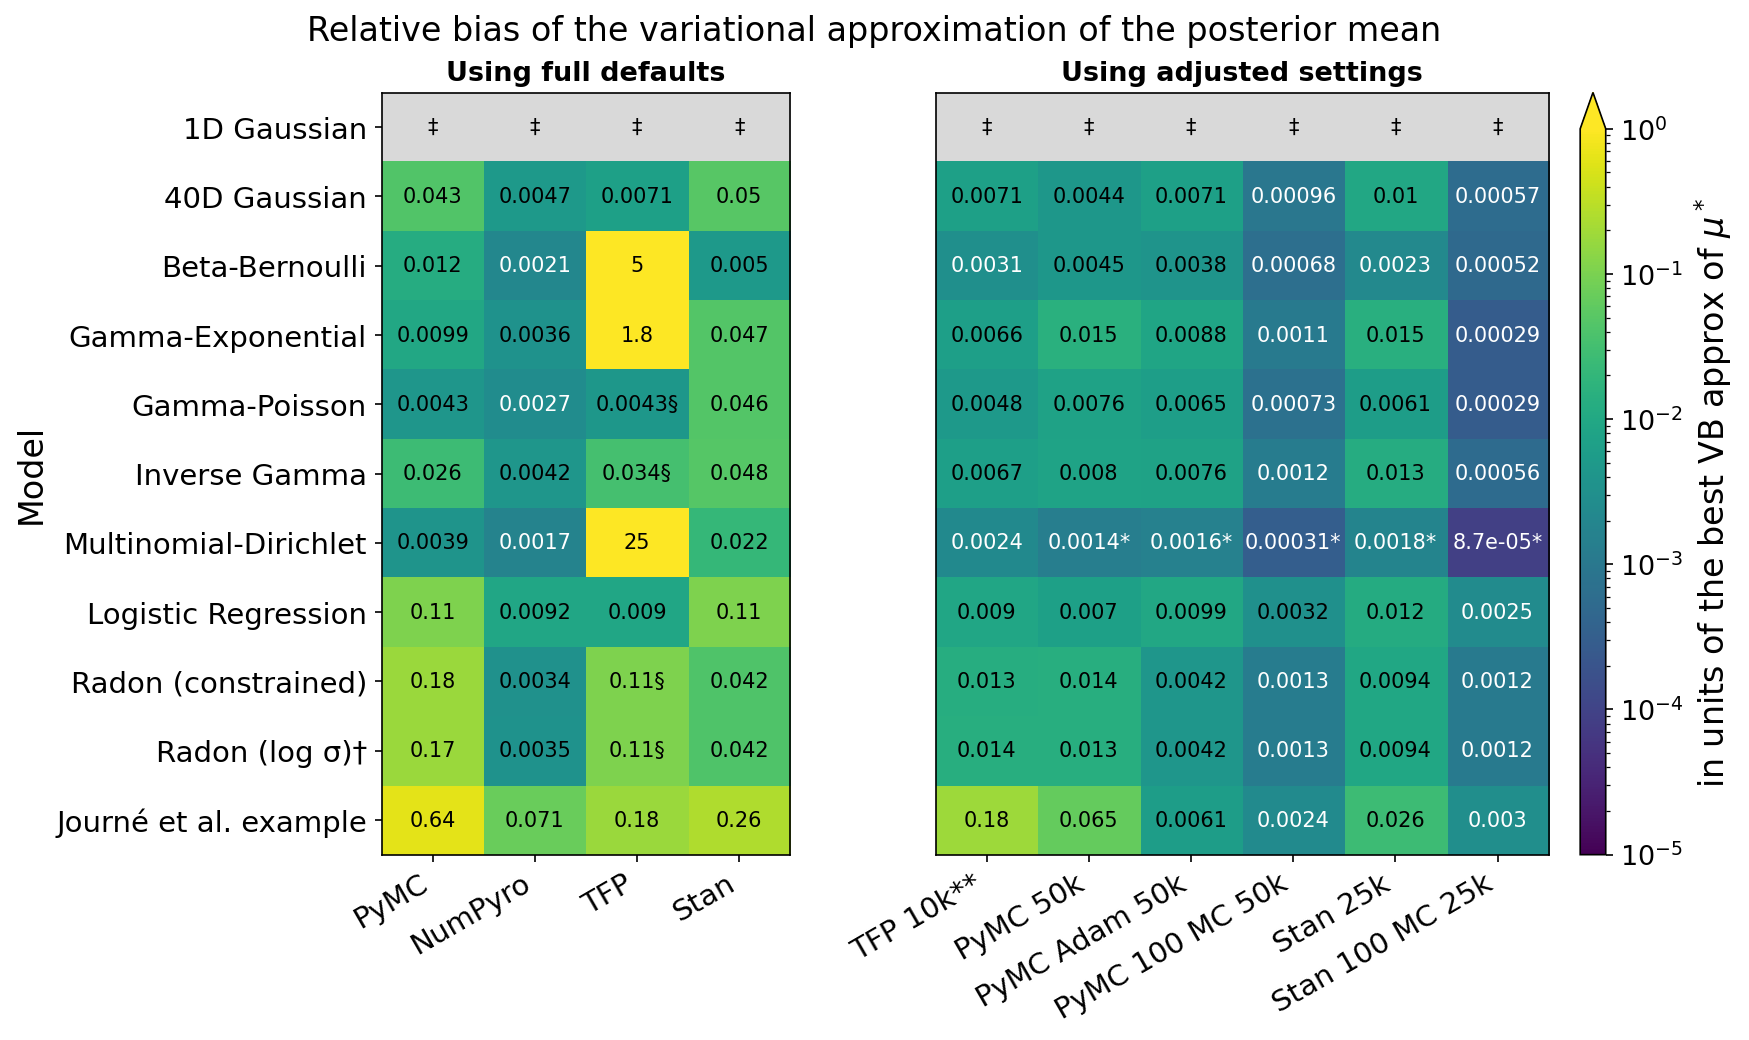

1. Mean over seeds of |⟨μ⟩ − μ*| / |μ*|; ⟨μ⟩, ⟨σ⟩ = VI posterior mean / SD averaged over the last 500 tracked iterations of each seed; multi-dimensional models: mean over coordinates.
§ some seeds failed (non-finite values in the tracked window, e.g. Stan's step-size adaptation failing); the cell averages over the other seeds. Failed seeds: Gamma-Poisson, TFP: 3 of 10 seeds failed; Inverse Gamma, TFP: 3 of 10 seeds failed; Radon (constrained), TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y); Radon (log σ)†, TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y).
* PyMC and Stan Multinomial-Dirichlet adjusted settings use an adjusted transform (their default simplex transforms replaced with the stick-breaking transform) to match the transform used in the other software packages; their full defaults use their own default simplex transforms.
Full defaults: each package as it comes, with 1 Monte Carlo sample p

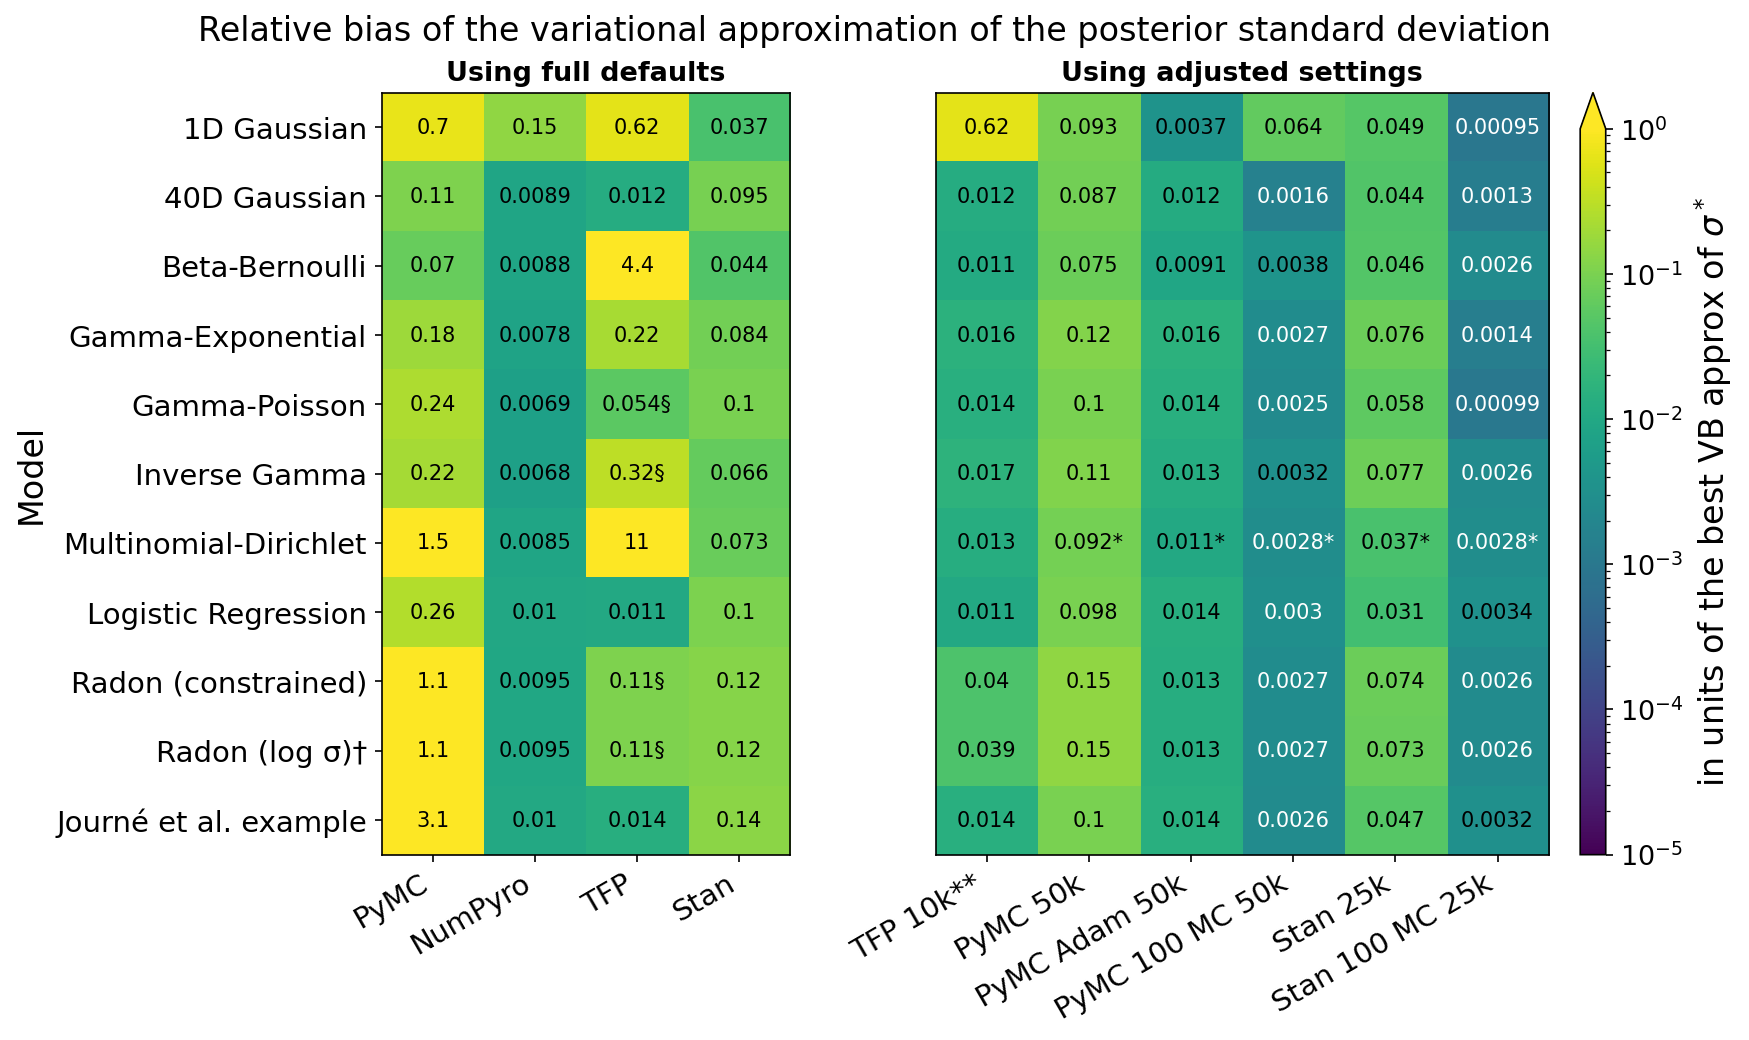

2. Mean over seeds of |⟨σ⟩ − σ*| / σ*; ⟨μ⟩, ⟨σ⟩ = VI posterior mean / SD averaged over the last 500 tracked iterations of each seed; multi-dimensional models: mean over coordinates.
§ some seeds failed (non-finite values in the tracked window, e.g. Stan's step-size adaptation failing); the cell averages over the other seeds. Failed seeds: Gamma-Poisson, TFP: 3 of 10 seeds failed; Inverse Gamma, TFP: 3 of 10 seeds failed; Radon (constrained), TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y); Radon (log σ)†, TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y).
* PyMC and Stan Multinomial-Dirichlet adjusted settings use an adjusted transform (their default simplex transforms replaced with the stick-breaking transform) to match the transform used in the other software packages; their full defaults use their own default simplex transforms.
Full defaults: each package as it comes, with 1 Monte Carlo sample per

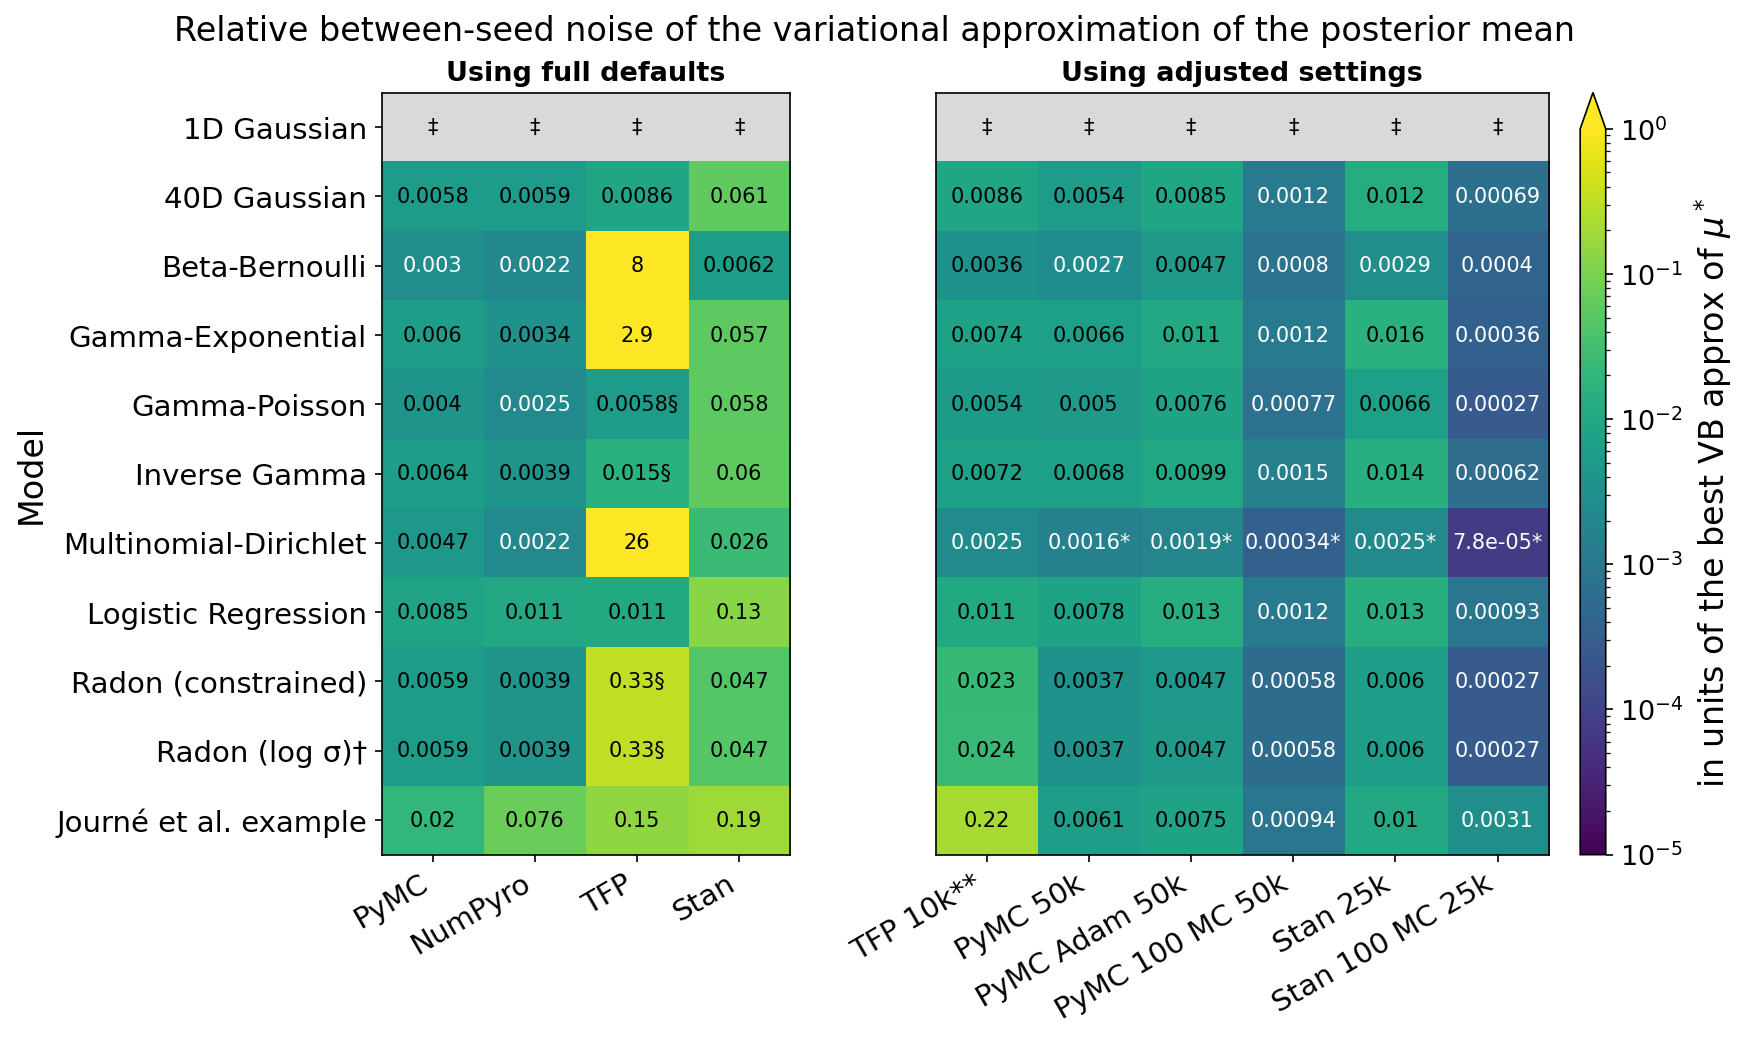

3. SD across seeds of (⟨μ⟩ divided by |μ*|); ⟨μ⟩, ⟨σ⟩ = VI posterior mean / SD averaged over the last 500 tracked iterations of each seed; multi-dimensional models: mean over coordinates.
§ some seeds failed (non-finite values in the tracked window, e.g. Stan's step-size adaptation failing); the cell averages over the other seeds. Failed seeds: Gamma-Poisson, TFP: 3 of 10 seeds failed; Inverse Gamma, TFP: 3 of 10 seeds failed; Radon (constrained), TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y); Radon (log σ)†, TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y).
* PyMC and Stan Multinomial-Dirichlet adjusted settings use an adjusted transform (their default simplex transforms replaced with the stick-breaking transform) to match the transform used in the other software packages; their full defaults use their own default simplex transforms.
Full defaults: each package as it comes, with 1 Monte Carlo samp

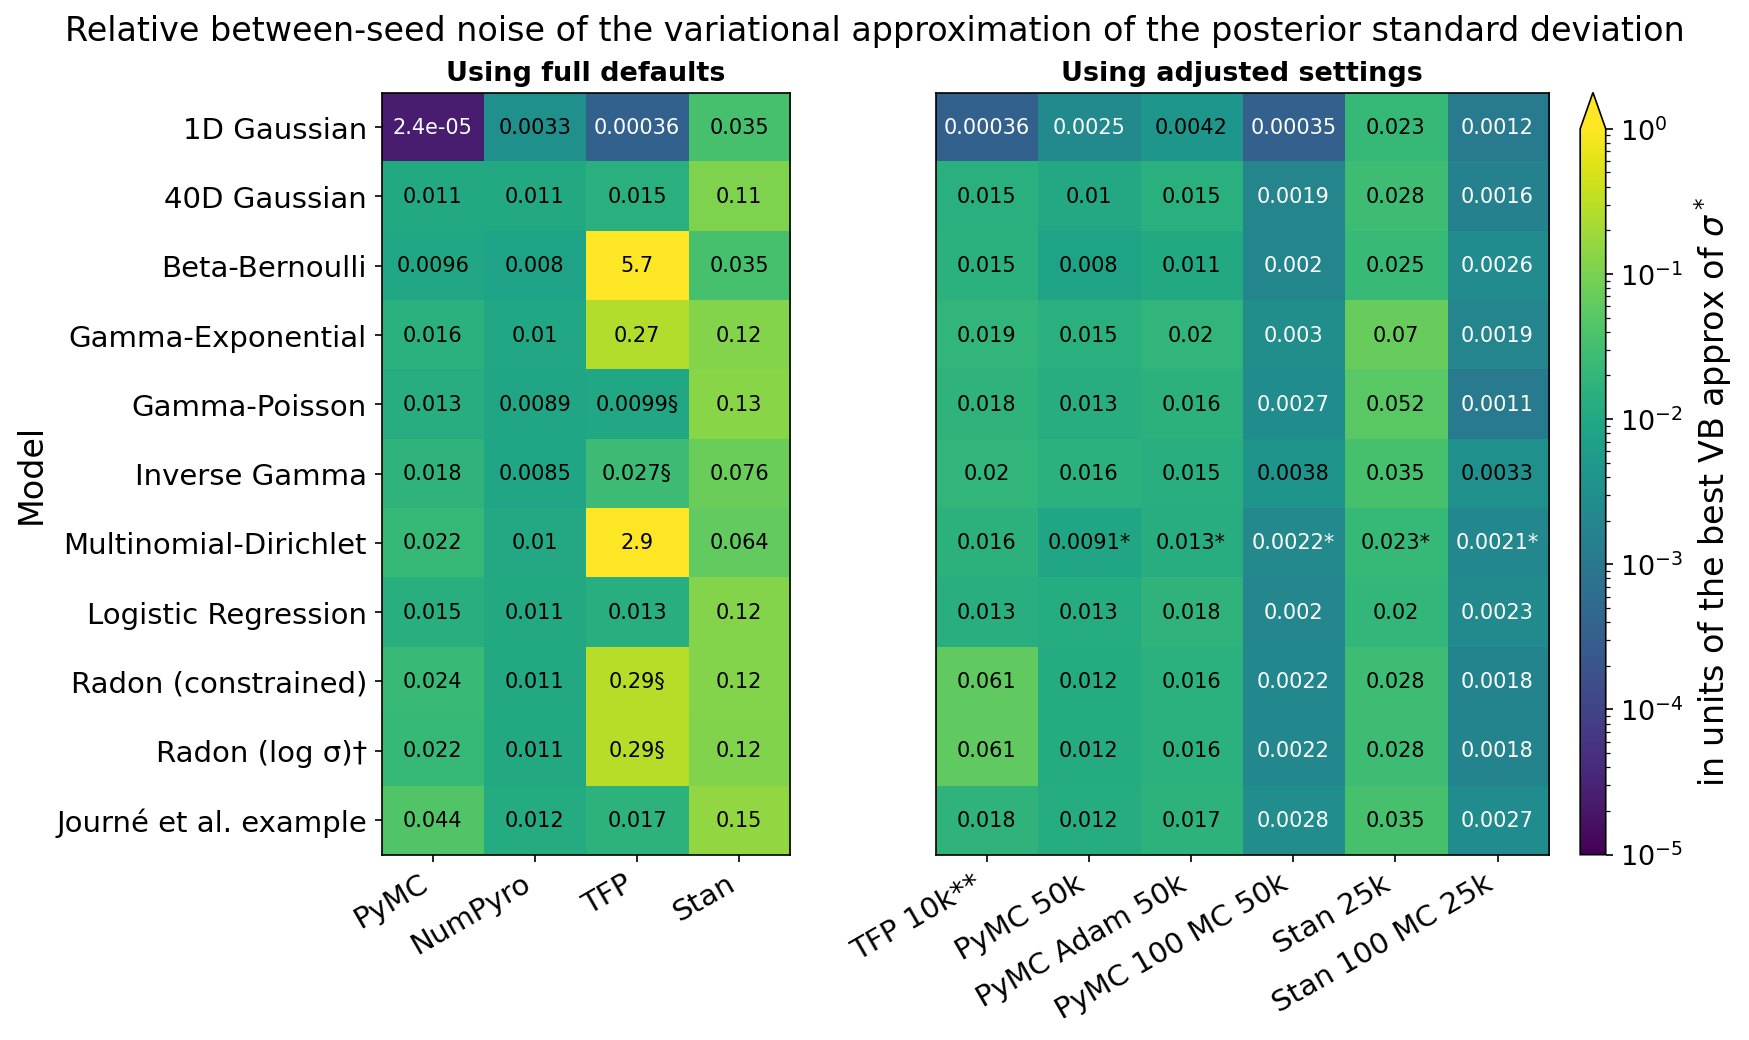

4. SD across seeds of (⟨σ⟩ divided by σ*); ⟨μ⟩, ⟨σ⟩ = VI posterior mean / SD averaged over the last 500 tracked iterations of each seed; multi-dimensional models: mean over coordinates.
§ some seeds failed (non-finite values in the tracked window, e.g. Stan's step-size adaptation failing); the cell averages over the other seeds. Failed seeds: Gamma-Poisson, TFP: 3 of 10 seeds failed; Inverse Gamma, TFP: 3 of 10 seeds failed; Radon (constrained), TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y); Radon (log σ)†, TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y).
* PyMC and Stan Multinomial-Dirichlet adjusted settings use an adjusted transform (their default simplex transforms replaced with the stick-breaking transform) to match the transform used in the other software packages; their full defaults use their own default simplex transforms.
Full defaults: each package as it comes, with 1 Monte Carlo sample

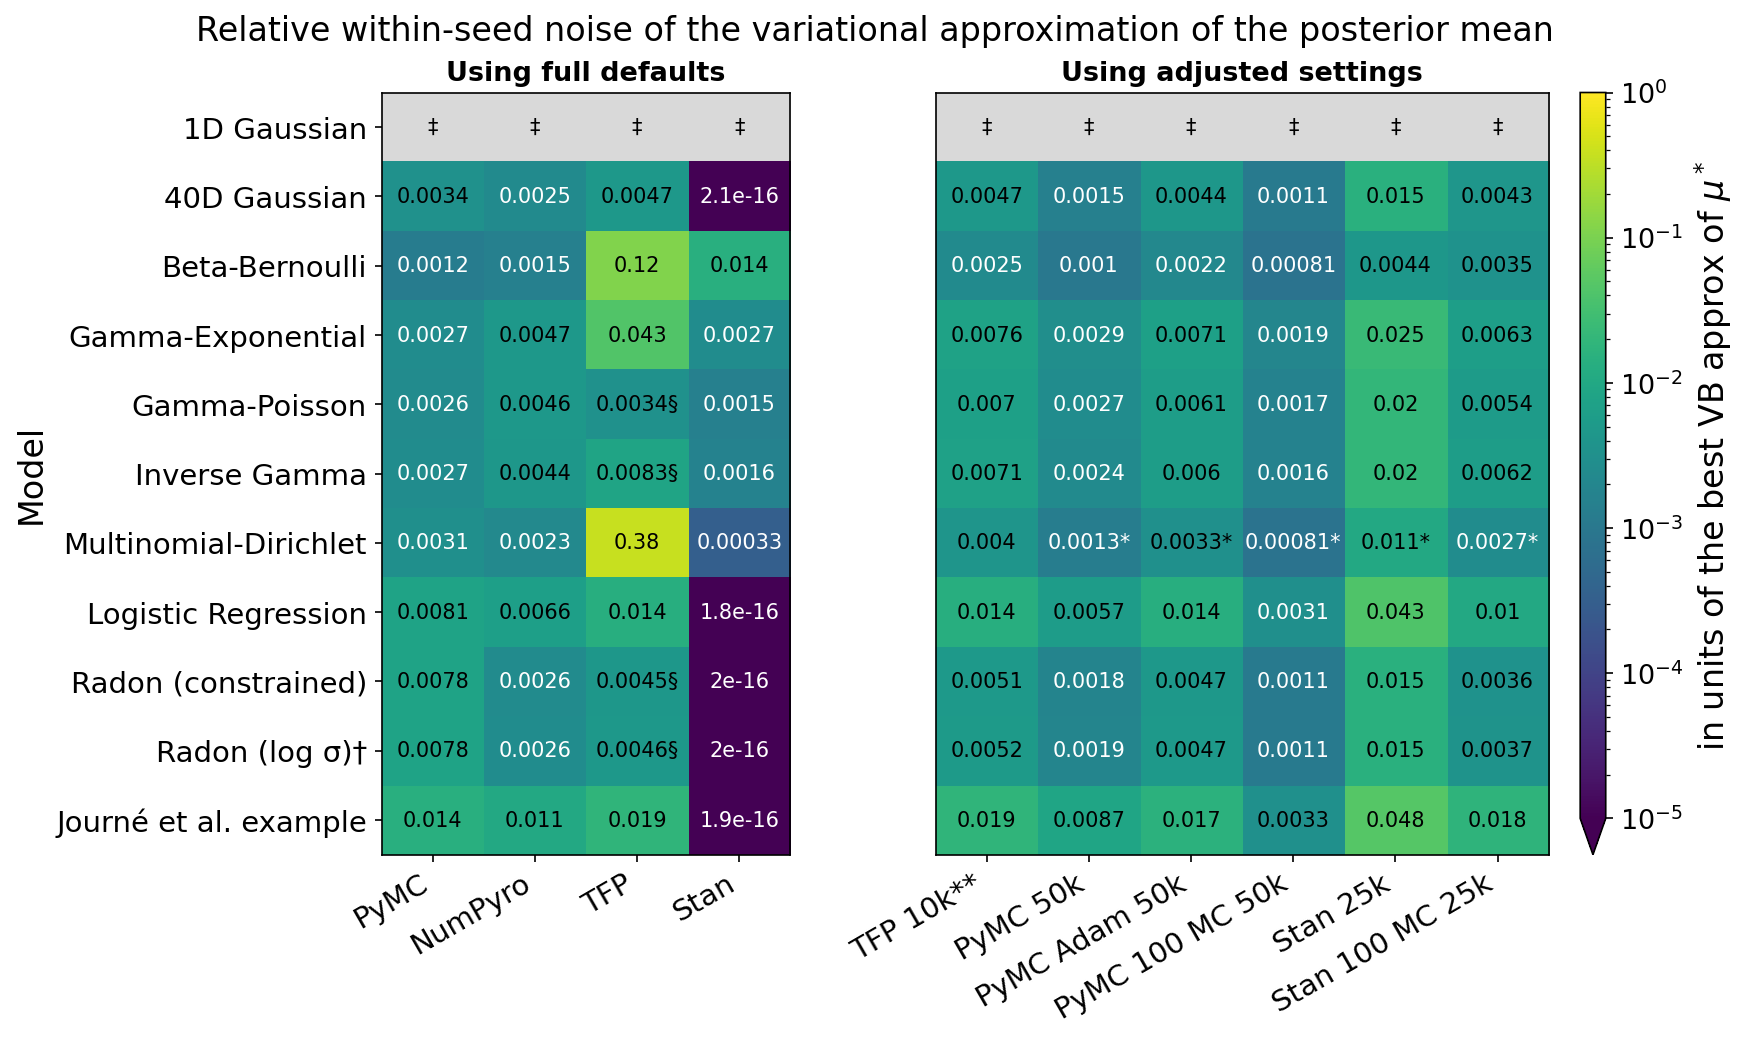

5. √(mean over seeds of the within-window variance of (μ divided by |μ*|)); ⟨μ⟩, ⟨σ⟩ = VI posterior mean / SD averaged over the last 500 tracked iterations of each seed; multi-dimensional models: mean over coordinates.
§ some seeds failed (non-finite values in the tracked window, e.g. Stan's step-size adaptation failing); the cell averages over the other seeds. Failed seeds: Gamma-Poisson, TFP: 3 of 10 seeds failed; Inverse Gamma, TFP: 3 of 10 seeds failed; Radon (constrained), TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y); Radon (log σ)†, TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y).
* PyMC and Stan Multinomial-Dirichlet adjusted settings use an adjusted transform (their default simplex transforms replaced with the stick-breaking transform) to match the transform used in the other software packages; their full defaults use their own default simplex transforms.
Full defaults: each package as it

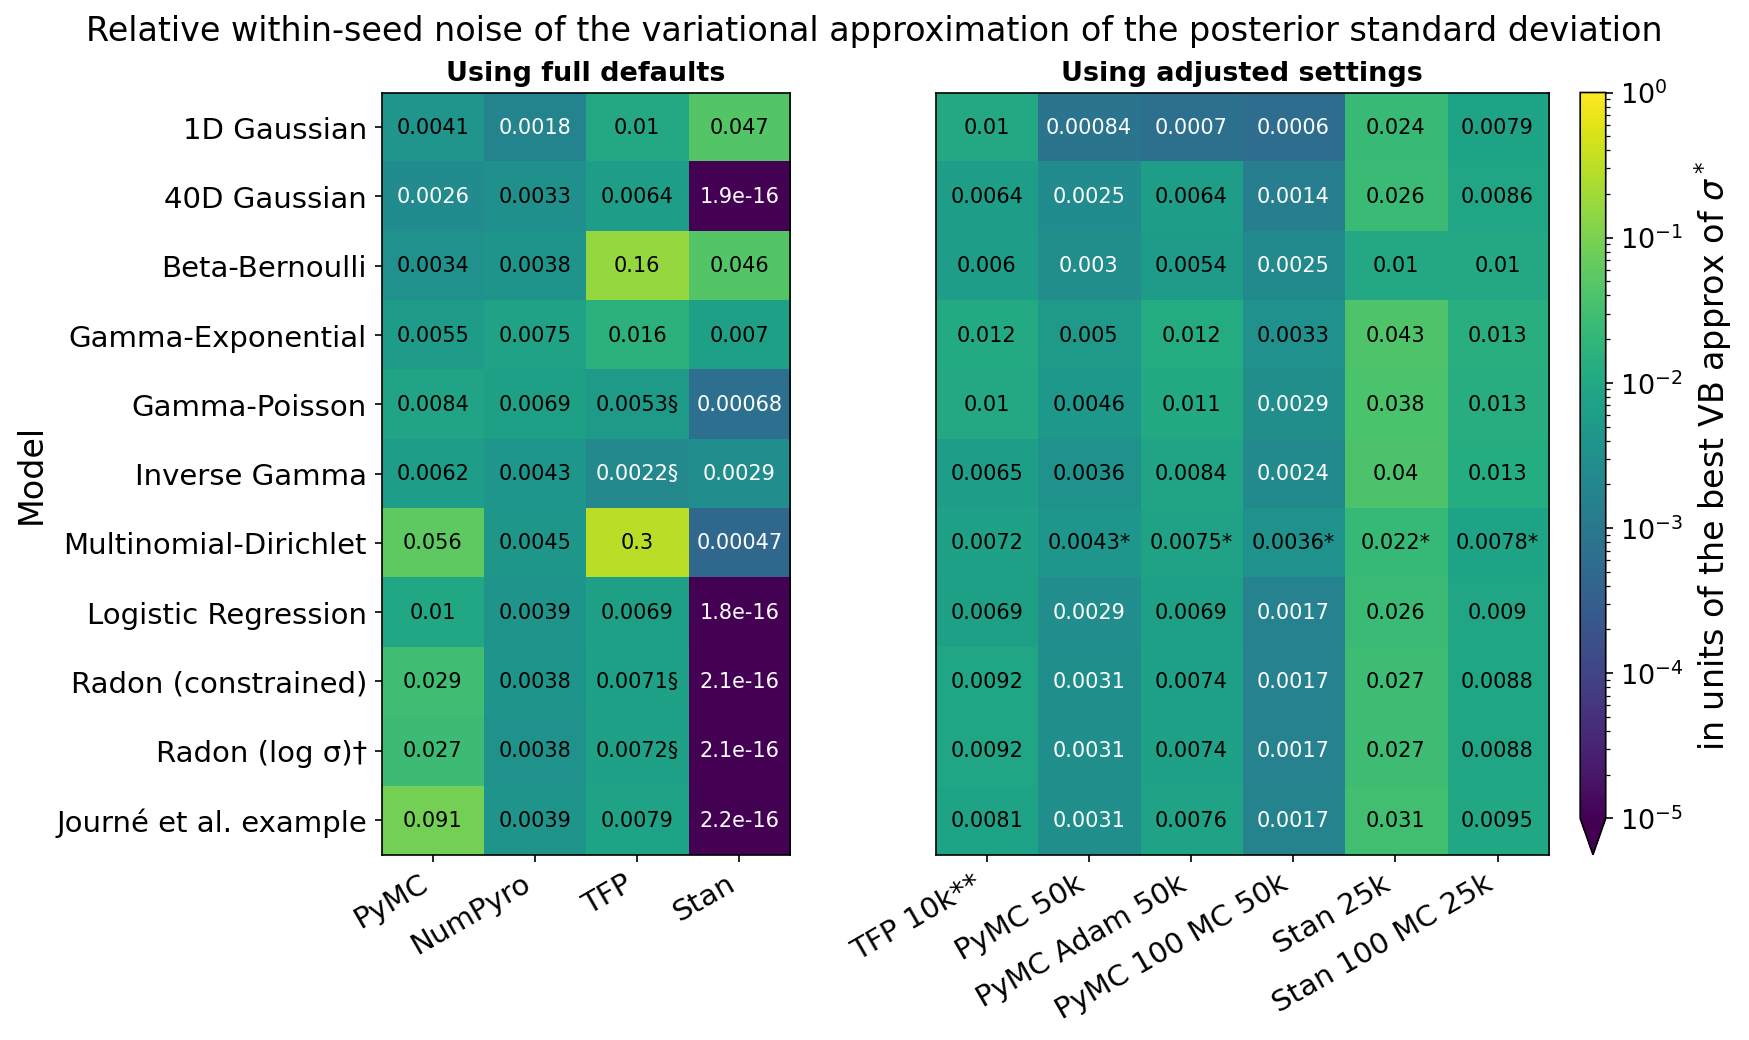

6. √(mean over seeds of the within-window variance of (σ divided by σ*)); ⟨μ⟩, ⟨σ⟩ = VI posterior mean / SD averaged over the last 500 tracked iterations of each seed; multi-dimensional models: mean over coordinates.
§ some seeds failed (non-finite values in the tracked window, e.g. Stan's step-size adaptation failing); the cell averages over the other seeds. Failed seeds: Gamma-Poisson, TFP: 3 of 10 seeds failed; Inverse Gamma, TFP: 3 of 10 seeds failed; Radon (constrained), TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y); Radon (log σ)†, TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y).
* PyMC and Stan Multinomial-Dirichlet adjusted settings use an adjusted transform (their default simplex transforms replaced with the stick-breaking transform) to match the transform used in the other software packages; their full defaults use their own default simplex transforms.
Full defaults: each package as it c

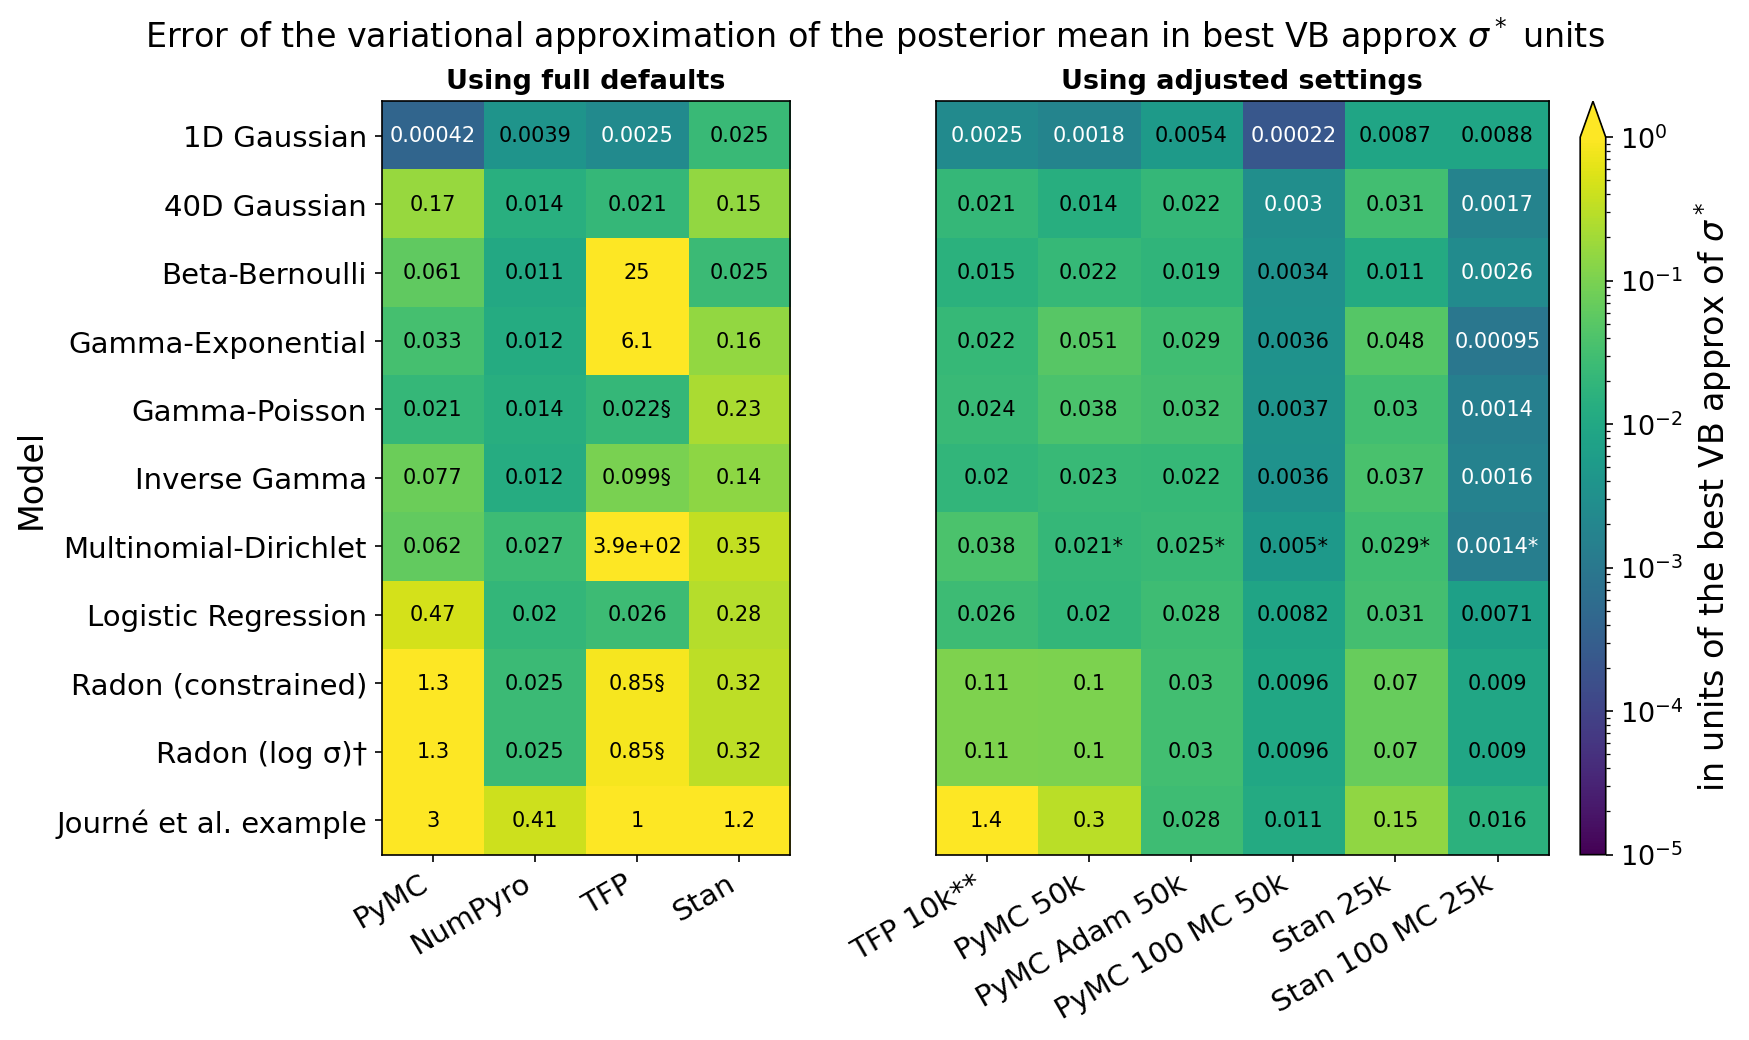

7. Mean over seeds of |⟨μ⟩ − μ*| / σ*; ⟨μ⟩, ⟨σ⟩ = VI posterior mean / SD averaged over the last 500 tracked iterations of each seed; multi-dimensional models: mean over coordinates.
§ some seeds failed (non-finite values in the tracked window, e.g. Stan's step-size adaptation failing); the cell averages over the other seeds. Failed seeds: Gamma-Poisson, TFP: 3 of 10 seeds failed; Inverse Gamma, TFP: 3 of 10 seeds failed; Radon (constrained), TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y); Radon (log σ)†, TFP: σ_a ≤ 0 in 7 of 10 seeds (left out of σ_a), σ_y ≤ 0 in 7 of 10 seeds (left out of σ_y).
* PyMC and Stan Multinomial-Dirichlet adjusted settings use an adjusted transform (their default simplex transforms replaced with the stick-breaking transform) to match the transform used in the other software packages; their full defaults use their own default simplex transforms.
Full defaults: each package as it comes, with 1 Monte Carlo sample per

In [7]:
# Primary heatmaps: one per metric. Rows are S.ROW_ORDER, columns are S.COLUMN_ORDER, and
# multi-dimensional models are combined over their coordinates with S.PRIMARY_COORD_AGG.
HM = bh.BiasHeatmaps(RESULTS, S)
PRIMARY_TABLES, PRIMARY_ZERO_FLAGS, PRIMARY_AVAILABLE = HM.build_primary_tables()
HM.set_shared_range([PRIMARY_TABLES])
PRIMARY_FIGURES = HM.plot_primary_heatmaps(PRIMARY_TABLES, PRIMARY_ZERO_FLAGS, PRIMARY_AVAILABLE)

### Run details

The settings each saved setup was run with (from its `run_info.json`).

In [8]:
bh.run_details(RESULTS)

,model,package,setup,seeds,max_iters,saved window,runtime (h),reference
0,1d_gaussian,numpyro,default,10,50000,500,0.01,"prior (no observations, as 3_1_numpyro.ipynb /..."
1,1d_gaussian,numpyro,100mc,10,50000,500,0.01,"prior (no observations, as 3_1_numpyro.ipynb /..."
2,1d_gaussian,numpyro,full_default,10,30000,500,0.00,"prior (no observations, as 3_1_numpyro.ipynb /..."
3,1d_gaussian,pymc,default,10,50000,500,0.08,"prior (no observations, as 3_1_pymc.ipynb / rr..."
4,1d_gaussian,pymc,100mc,10,50000,500,0.08,"prior (no observations, as 3_1_pymc.ipynb / rr..."
...,...,...,...,...,...,...,...,...
160,radon_log,stan,full_default,10,10000,500,0.02,single_MC/radon_example/pymc_tutorial/best_ref...
161,radon_log,tfp,default,10,50000,500,0.06,single_MC/radon_example/pymc_tutorial/best_ref...
162,radon_log,tfp,100mc,10,50000,500,0.06,single_MC/radon_example/pymc_tutorial/best_ref...
163,radon_log,tfp,default_10k,10,10000,500,0.00,single_MC/radon_example/pymc_tutorial/best_ref...


## Fit times of the full defaults

Wall-clock seconds of each seed's fit (`seed_seconds` in each `run_info.json`): the whole call
including model building and compilation, so a package's first seed of a model can be slower than the
rest (compilation is cached afterwards); the median is the typical fit. Stan's time is its CmdStan run
with `iter=10000` (including process start-up and writing the 1,000 output draws). The packages ran one
after the other; Stan's seeds ran as parallel CmdStan processes.

The table lists the median, mean, min and max over the 10 seeds; the heatmap below it shows the median seconds per fit for every model and package (log colour scale), with each cell's min–max range.

In [9]:
FIT_TIMES = bh.fit_times(RESULTS, FULL)
FIT_TIME_SUMMARY = (FIT_TIMES.groupby(["model", "package"])["seconds"]
                    .agg(median="median", mean="mean", min="min", max="max", seeds="count")
                    .round(2))
display(FIT_TIME_SUMMARY)
# median seconds per fit: model x package
FIT_TIME_TABLE = (FIT_TIME_SUMMARY["median"].unstack("package")
                  .reindex(index=[r for r in S.ROW_ORDER if r in FIT_TIME_SUMMARY.index.get_level_values(0)
                                  and r != "radon_log"],      # radon: one fit saved on two scales
                           columns=[p for p in bias_io.PACKAGE_SETUPS if p in FIT_TIMES["package"].unique()])
                  .rename(index={**S.ROW_LABELS, "radon_constrained": "Radon"}, columns=S.PACKAGE_LABELS))
FIT_TIME_TABLE

median  mean   min   max  seeds
model                 package                                 
1d_gaussian           numpyro    0.56  0.59  0.54  0.84     10
                      pymc       0.47  0.65  0.46  2.23     10
                      stan       0.02  0.02  0.02  0.03     10
                      tfp        0.64  0.65  0.60  0.79     10
40d_gaussian          numpyro    0.86  0.88  0.81  1.02     10
                      pymc       0.52  0.61  0.49  1.41     10
                      stan       0.02  0.02  0.02  0.03     10
                      tfp        1.55  1.55  1.49  1.63     10
beta_binomial         numpyro    0.73  0.75  0.69  0.89     10
                      pymc       0.64  0.78  0.62  2.02     10
                      stan       0.02  0.02  0.02  0.03     10
                      tfp        0.85  0.86  0.78  1.01     10
dirichlet_multinomial numpyro    0.83  0.86  0.77  1.13     10
                      pymc       0.91  1.04  0.83  2.31     10
                      stan       0.02  0.02  0.01  0.02     10
                      tfp        0.70  0.71  0.66  0.76     10
gamma_exponential     numpyro    0.60  0.60  0.55  0.71     10
                      pymc       0.54  0.62  0.51  1.45     10
                      stan       0.04  0.04  0.01  0.05     10
                      tfp        0.71  0.71  0.68  0.74     10
gamma_poisson         numpyro    0.64  0.65  0.59  0.76     10
                      pymc       0.59  0.70  0.57  1.70     10
                      stan       0.03  0.03  0.01  0.05     10
                      tfp        0.67  0.68  0.66  0.73     10
inverse_gamma         numpyro    0.74  0.75  0.69  0.87     10
                      pymc       0.59  0.68  0.55  1.60     10
                      stan       0.03  0.03  0.02  0.04     10
                      tfp        0.69  0.70  0.68  0.75     10
journe                numpyro    4.71  4.80  4.55  5.38     10
                      pymc       1.36  1.56  1.33  3.44     10
                      stan       0.58  0.58  0.40  0.93     10
                      tfp        4.60  4.57  4.25  4.86     10
logistic_regression   numpyro    0.69  0.70  0.65  0.81     10
                      pymc       0.45  1.02  0.44  6.13     10
                      stan       0.02  0.02  0.01  0.03     10
                      tfp        0.75  0.78  0.71  1.02     10
radon_constrained     numpyro    4.00  4.05  3.81  4.36     10
                      pymc       1.01  1.09  0.96  1.87     10
                      stan       0.07  0.07  0.06  0.08     10
                      tfp        0.95  0.95  0.91  1.04     10
radon_log             numpyro    4.00  4.05  3.81  4.36     10
                      pymc       1.01  1.09  0.96  1.87     10
                      stan       0.07  0.07  0.06  0.08     10
                      tfp        0.95  0.95  0.91  1.04     10

package,PyMC,TFP,NumPyro,Stan
model,,,,
1D Gaussian,0.47,0.64,0.56,0.02
40D Gaussian,0.52,1.55,0.86,0.02
Beta-Bernoulli,0.64,0.85,0.73,0.02
Gamma-Exponential,0.54,0.71,0.60,0.04
Gamma-Poisson,0.59,0.67,0.64,0.03
Inverse Gamma,0.59,0.69,0.74,0.03
Multinomial-Dirichlet,0.91,0.70,0.83,0.02
Logistic Regression,0.45,0.75,0.69,0.02
Radon,1.01,0.95,4.00,0.07


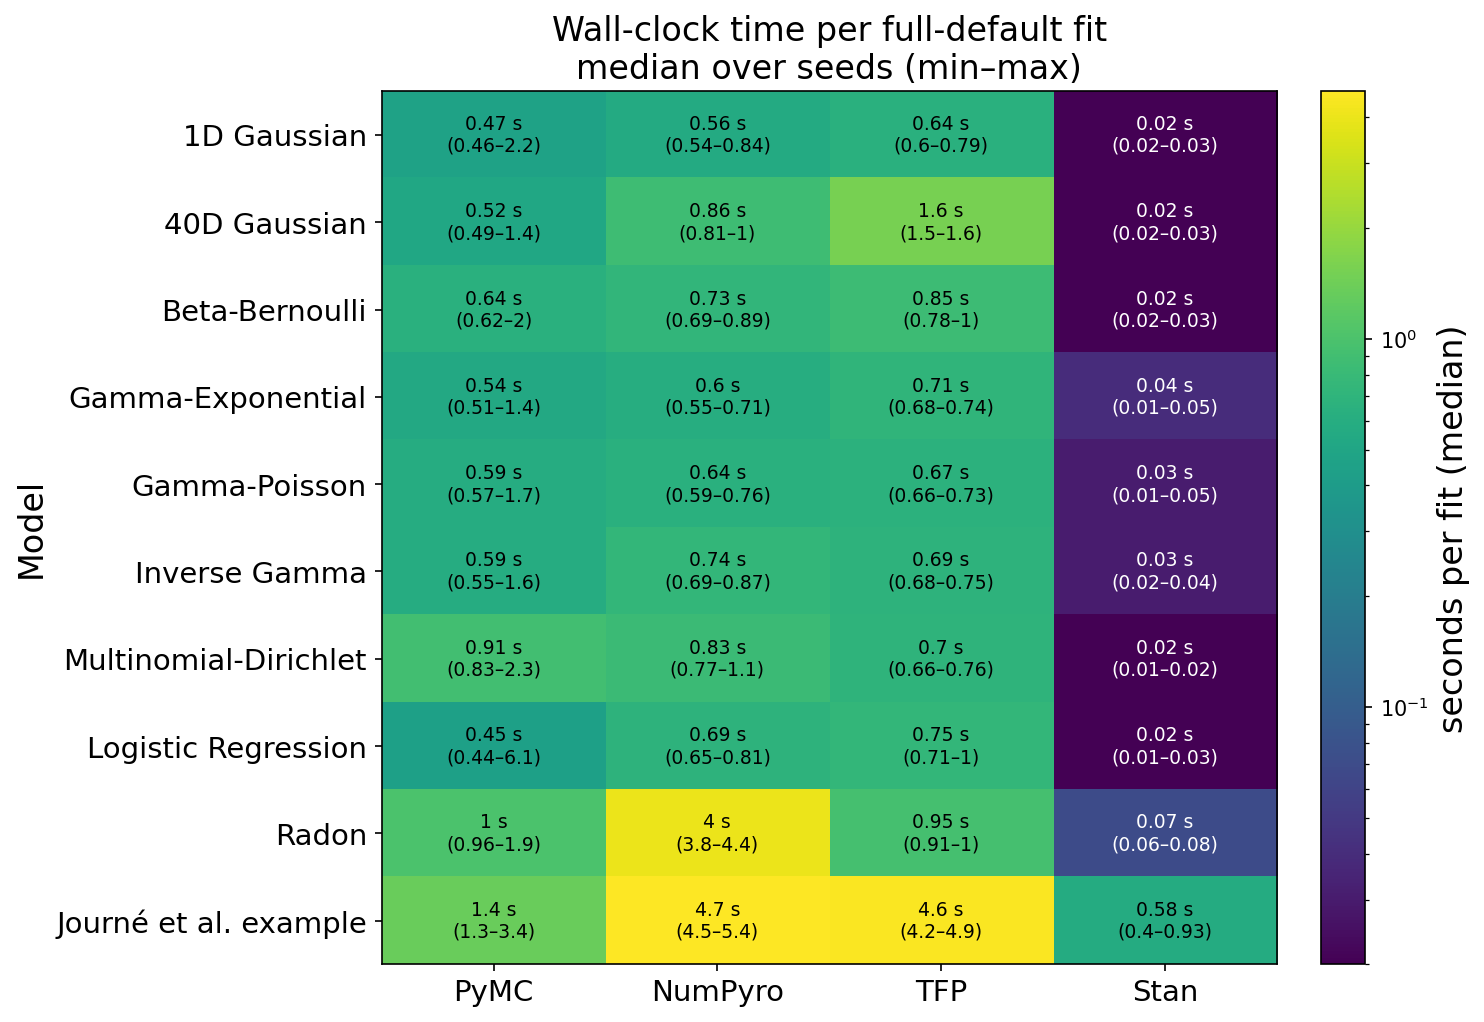

Iterations per fit: PyMC, TFP and Stan 10,000 (Stan stops earlier once tol_rel_obj=0.01 is met), NumPyro 30,000. Times include model building and compilation (a package's first seed of a model can be slower); Stan's seeds ran as parallel CmdStan processes, the other packages one fit at a time.


In [10]:
# Median wall-clock seconds per full-default fit: one row per model, one column per package (as the left panel)
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

time_columns = [p for p, _ in S.COLUMN_GROUPS[0] if p in FIT_TIMES["package"].unique()]
# radon is one fit saved on two scales, so it gets one row (its constrained-scale copy, which every package has)
time_rows = [m for m in S.ROW_ORDER if m in set(FIT_TIMES["model"]) and m != "radon_log"]
time_labels = {**S.ROW_LABELS, "radon_constrained": "Radon"}
summary = FIT_TIME_SUMMARY.reset_index()
median = summary.pivot(index="model", columns="package", values="median").reindex(index=time_rows, columns=time_columns)
low = summary.pivot(index="model", columns="package", values="min").reindex(index=time_rows, columns=time_columns)
high = summary.pivot(index="model", columns="package", values="max").reindex(index=time_rows, columns=time_columns)

values = median.to_numpy(dtype=float)
finite = values[np.isfinite(values) & (values > 0)]
norm = LogNorm(vmin=finite.min(), vmax=finite.max()) if finite.size else None
cmap = plt.get_cmap(S.COLORSCALE).copy()
cmap.set_bad(S.MISSING_COLOR)
fig, ax = plt.subplots(figsize=(3 + 1.7 * len(time_columns), 1.2 + 0.55 * len(time_rows)), dpi=S.MATPLOTLIB_DPI,
                       layout="constrained")
image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=norm, aspect="auto")


def seconds_text(x):
    return f"{x:.2g}" if x < 10 else f"{x:.0f}"


for i in range(len(time_rows)):
    for j in range(len(time_columns)):
        if not np.isfinite(values[i, j]):
            ax.text(j, i, S.MISSING_TEXT, ha="center", va="center", fontsize=S.FONT_SIZE - 4)
            continue
        label = f"{seconds_text(values[i, j])} s\n({seconds_text(low.iloc[i, j])}–{seconds_text(high.iloc[i, j])})"
        ax.text(j, i, label, ha="center", va="center", fontsize=S.FONT_SIZE - 5,
                color="white" if norm(values[i, j]) < 0.5 else "black")
ax.set_xticks(range(len(time_columns)), labels=[S.PACKAGE_LABELS.get(p, p) for p in time_columns], fontsize=S.LABEL_FONT_SIZE)
ax.set_yticks(range(len(time_rows)), labels=[time_labels.get(m, m) for m in time_rows], fontsize=S.LABEL_FONT_SIZE)
ax.set_ylabel(S.Y_AXIS_TITLE, fontsize=S.VERTICAL_LABEL_FONT_SIZE)
ax.set_title("Wall-clock time per full-default fit\nmedian over seeds (min–max)", fontsize=S.TITLE_FONT_SIZE)
cbar = fig.colorbar(image, ax=ax)
cbar.set_label("seconds per fit (median)", fontsize=S.VERTICAL_LABEL_FONT_SIZE)
if S.SAVE_FIGURES or S.SAVE_TABLES:
    Path(S.FIGURE_DIR).mkdir(parents=True, exist_ok=True)
    if S.SAVE_FIGURES:
        fig.savefig(Path(S.FIGURE_DIR) / f"full_default_fit_times.{S.FIGURE_FORMAT['matplotlib']}", bbox_inches="tight")
    if S.SAVE_TABLES:
        FIT_TIME_SUMMARY.to_csv(Path(S.FIGURE_DIR) / "full_default_fit_times.csv")
plt.show()
print("Iterations per fit: PyMC, TFP and Stan 10,000 (Stan stops earlier once tol_rel_obj=0.01 is met), NumPyro 30,000. "
      "Times include model building and compilation (a package's first seed of a model can be slower); "
      "Stan's seeds ran as parallel CmdStan processes, the other packages one fit at a time.")